# Kernel checks
Analytical curves and full RBF-kernel checks for Figures 6 and 7. Set the two flags below to rerun the simulations.


In [1]:
# Run top-to-bottom. Default: recompute theory and load stored simulation records.
# The two FORCE_RECOMPUTE flags enable fresh simulations instead.
# Requires NumPy, SciPy, Matplotlib, threadpoolctl and IPython.
from pathlib import Path
from dataclasses import dataclass, asdict
from functools import lru_cache
import json, math, platform
import numpy as np
import scipy
from scipy.optimize import brentq, minimize_scalar
from scipy.special import erfc, roots_legendre
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, MaxNLocator, FixedLocator, FuncFormatter
from matplotlib.colors import Normalize
from threadpoolctl import threadpool_limits
try:
    from IPython.display import display, Image
except ImportError:
    def Image(filename): return str(filename)
    def display(value): print(value)

OUT = Path("Figures")
OUT.mkdir(parents=True, exist_ok=True)
PLOT_STYLE = {
    "font.family": "serif", "font.size": 18, "mathtext.fontset": "dejavuserif",
    "text.usetex": False, "axes.labelsize": 21, "axes.titlesize": 17,
    "xtick.labelsize": 17, "ytick.labelsize": 17, "legend.fontsize": 14,
    "axes.linewidth": 1.0, "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
}
COLORS = ("#0072B2", "#D55E00", "#009E73")
NQUAD = 1600

def save_figure(fig, stem):
    for extension in ("pdf", "png"):
        path = OUT / f"{stem}.{extension}"
        fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
        print(f"Saved: {path}")
    plt.close(fig)

def save_json(name, value):
    
    def clean(x):
        if isinstance(x, dict): return {k: clean(v) for k, v in x.items()}
        if isinstance(x, (list, tuple)): return [clean(v) for v in x]
        if isinstance(x, np.ndarray): return clean(x.tolist())
        if isinstance(x, (np.integer,)): return int(x)
        if isinstance(x, (np.floating, float)):
            return "infinity" if np.isposinf(x) else float(x)
        return x
    (OUT/name).write_text(json.dumps(clean(value), indent=2)+"\n")

print("Python", platform.python_version(), "NumPy", np.__version__,
      "SciPy", scipy.__version__, "Matplotlib", matplotlib.__version__)
print("All PDFs will be saved in", OUT)

import os
PROJECT_ROOT = Path.cwd()
FORCE_RECOMPUTE_THEORY_VALIDATION = False
CIFAR_FORCE_RECOMPUTE = False

_thread_limit = threadpool_limits(limits=1)


Python 3.12.15 NumPy 2.5.4 SciPy 1.18.1 Matplotlib 3.11.2
All PDFs will be saved in Figures


In [2]:



import hashlib
import json
import tempfile
import zipfile

class CacheMismatch(ValueError):
    pass

CACHE_READ_ERRORS = (CacheMismatch, ValueError, KeyError, TypeError, IndexError,
                     OSError, EOFError, zipfile.BadZipFile)

def scientific_digest(value):
    text = json.dumps(value, sort_keys=True, separators=(',', ':'), allow_nan=False)
    return hashlib.sha256(text.encode()).hexdigest()[:20]

def atomic_npz(path, **arrays):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix='.npz', delete=False) as f:
        temporary = Path(f.name)
        try:
            np.savez_compressed(f, **arrays)
        except BaseException:
            temporary.unlink(missing_ok=True)
            raise
    try:
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)

def publication_cache(relative_name):
    path = Path('kernel_data') / relative_name
    if not path.is_file():
        raise FileNotFoundError(path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != PUBLICATION_HASHES[relative_name]:
        raise ValueError('The stored kernel records have changed.')
    return path

def checked_cache(candidates, reader):
    
    for path in dict.fromkeys(map(Path, candidates)):
        if not path.is_file():
            continue
        try:
            result = reader(path)
        except CACHE_READ_ERRORS as error:
            print(f'Skipping incompatible cache {path.name}: {error}', flush=True)
            continue
        print(f'Loaded matching data: {path.name}', flush=True)
        return result
    return None

def require_close(observed, expected, label, rtol=1e-12, atol=0):
    observed, expected = np.asarray(observed), np.asarray(expected)
    if observed.shape != expected.shape or not np.allclose(observed, expected, rtol=rtol, atol=atol):
        raise CacheMismatch(f'{label} differs from the requested experiment.')

def classification_array(value, shape, label, count=None):
    value = np.asarray(value, dtype=float)
    if value.shape != tuple(shape) or not np.all(np.isfinite(value)) or np.any((value < 0) | (value > 1)):
        raise CacheMismatch(f'{label} has invalid shape or classification errors.')
    if count is not None:
        if count < 1 or not np.allclose(value*count, np.rint(value*count), atol=1e-8, rtol=0):
            raise CacheMismatch(f'{label} does not represent integer counts out of {count}.')
    return value


PUBLICATION_HASHES = {'kernel_validation_raw_rbf_data.npz': 'c28d9195e7097c5266aa95a705ae1a30a35b1af6a119fa76cdf00fbb765e6164', 'cifar_cache/cifar_kernel_results.npz': '90a86f8d3f786f763201ab5769ce3506062c5bff41f016565f29cf5c598b5181'}


In [3]:

from dataclasses import dataclass, asdict
from functools import lru_cache
from pathlib import Path
import json
import math
import numpy as np
from scipy.optimize import brentq
from scipy.special import erfc

@dataclass(frozen=True)
class validation_Case:
    name: str
    alpha: float
    epsilon: float
    b: float
    delta0: float = 0.
    metric: str = 'rkhs'
    def __post_init__(self):
        if not (self.alpha>0 and 0<=self.epsilon<1 and self.b>0 and self.delta0>=0):
            raise ValueError('Require alpha>0, 0<=epsilon<1, b>0, delta0>=0')
        if self.metric not in ('rkhs','dual'):
            raise ValueError('metric must be rkhs or dual')
    @property
    def a(self): return (1-self.epsilon)*np.sqrt(2/np.pi)
    @property
    def bc(self): return (1-self.a**2)/self.a**2
    @property
    def gamma_pi(self): return np.arctan(1/np.sqrt(self.b))/np.pi
    @property
    def power(self): return {'rkhs':1,'dual':2}[self.metric]

@lru_cache(maxsize=256)
def validation_quadrature(alpha,n=1600):
    theta=(np.arange(n)+.5)*np.pi/n
    s=(np.sqrt(alpha)-1)**2+4*np.sqrt(alpha)*np.sin(theta/2)**2
    wn=2*alpha*np.sin(theta)**2/(n*s)
    wr=wn/alpha
    return s,wn,wr,max(1-alpha,0.),max(1-1/alpha,0.)

def validation_curves(c,times,n=1600,chunk=128):
    tt=np.atleast_1d(np.asarray(times,dtype=float))
    if np.any(tt<0) or np.any(np.isnan(tt)): raise ValueError('Nonnegative times required')
    s,wn,wr,_,ar=validation_quadrature(c.alpha,n)
    a,b=c.a,c.b; rate=(s+b)**c.power
    W=s*(a*a*s+1-a*a)/(s+b)**2
    arrays={k:np.empty(len(tt)) for k in ('m','q','V','Q','E_test','E_mem')}
    for lo in range(0,len(tt),chunk):
        sl=slice(lo,min(lo+chunk,len(tt))); t=tt[sl,None]
        r=np.exp(-t*rate); h=-np.expm1(-t*rate); f=s/(s+b)*h
        m=a*(f@wn)
        q=(W*h*h)@wn+c.delta0*((s*r*r)@wn)
        r0=np.exp(-tt[sl]*b**c.power); h0=-np.expm1(-tt[sl]*b**c.power)
        V=h@wr+ar*h0
        dh=h-V[:,None]
        Q=((1-a*a+a*a*s)*dh*dh)@wr+(1-a*a)*ar*(h0-V)**2
        Q+=c.delta0*(((s+b)**2*r*r)@wr+ar*b*b*r0*r0)
        corr=np.divide(m,np.sqrt(q),out=np.zeros_like(m),where=q>0)
        Et=np.arccos(np.clip(corr,-1,1))/np.pi
        Em=np.full(len(m),.5); pos=Q>0
        Em[pos]=.5*erfc(V[pos]/np.sqrt(2*Q[pos])); Em[~pos & (V>0)]=0.
        for name,value in zip(arrays,(m,q,V,Q,Et,Em)): arrays[name][sl]=value
    return {'tau':tt,**arrays}

def validation_right_limit(c,n=1600):
    if c.delta0>0: return .5,.5
    s,wn,wr,_,ar=validation_quadrature(c.alpha,n); a,b=c.a,c.b
    rate=(s+b)**c.power; v=rate@wr+ar*b**c.power
    q=((1-a*a+a*a*s)*(rate-v)**2)@wr+(1-a*a)*ar*(b**c.power-v)**2
    f=s*(s+b)**(c.power-1)
    m=a*(f@wn); qt=((a*a+(1-a*a)/s)*f*f)@wn
    return float(np.arccos(np.clip(m/np.sqrt(qt),-1,1))/np.pi),float(.5*erfc(v/np.sqrt(2*q)))

def validation_stationarity(c,t,n=1600):
    s,wn,_,_,_=validation_quadrature(c.alpha,n); a,b=c.a,c.b
    rate=(s+b)**c.power; r=np.exp(-t*rate); h=-np.expm1(-t*rate)
    p=s/(s+b); W=s*(a*a*s+1-a*a)/(s+b)**2
    M=(p*h)@wn; q=(W*h*h)@wn+c.delta0*((s*r*r)@wn)
    if c.delta0==0 and t*rate.max()<.05:
        
        
        L=-rate/2+t*rate**2/12-t**3*rate**4/720+t**5*rate**6/30240
        Mp_centered=((p*h)*L)@wn
        qp_centered=2*((W*h*h)*L)@wn
        return float(2*Mp_centered*q-M*qp_centered)
    rs=np.exp(-t*(rate-rate.min()))
    Mp=(p*rate*rs)@wn
    qp=2*((W*h*rate*rs)@wn)-2*c.delta0*((s*rate*r*rs)@wn)
    return float(2*Mp*q-M*qp)

def validation_stopping_time(c,n=1600):
    
    if c.b>=c.bc or np.isclose(c.b,c.bc,rtol=2e-13,atol=0): return math.inf
    s,_,_,_,_=validation_quadrature(c.alpha,n); rates=(s+c.b)**c.power
    ts=np.geomspace(1e-9/rates.max(),max(80/rates.min(),1),500)
    ds=np.array([validation_stationarity(c,float(t),n) for t in ts]); ids=np.flatnonzero((ds[:-1]>0)&(ds[1:]<0))
    cand=[]
    for j in ids:
        root=brentq(lambda t:validation_stationarity(c,t,n),ts[j],ts[j+1],xtol=1e-12)
        cand.append(float(root))
    if not cand: raise ArithmeticError('No finite optimum bracketed')
    return cand[int(np.argmin(validation_curves(c,cand,n)['E_test']))]

def validation_memorization_time(c,tolerance=.01,n=1600):
    if not 0<tolerance<.5: raise ValueError('Use 0<tolerance<1/2')
    if c.delta0==0 and validation_right_limit(c,n)[1]<=tolerance: return 0.
    s,_,_,_,ar=validation_quadrature(c.alpha,n); rates=(s+c.b)**c.power
    min_rate=min(rates.min(),c.b**c.power) if ar else rates.min()
    ts=np.geomspace(1e-11/rates.max(),max(100/min_rate,1),450)
    ee=validation_curves(c,ts,n)['E_mem']; ii=np.flatnonzero(ee<=tolerance)
    if not len(ii): return math.inf
    j=ii[0]
    if j==0: raise ArithmeticError('Unresolved 0+ threshold crossing')
    return float(np.exp(brentq(lambda z:validation_curves(c,[np.exp(z)],n)['E_mem'][0]-tolerance,np.log(ts[j-1]),np.log(ts[j]),xtol=1e-10)))

def validation_summarize(c,n=1600):
    es=validation_stopping_time(c,n); mem=validation_memorization_time(c,n=n)
    best=float(validation_curves(c,[es],n)['E_test'][0]); end=float(validation_curves(c,[np.inf],n)['E_test'][0]); atmem=validation_right_limit(c,n)[0] if mem==0 else float(validation_curves(c,[mem],n)['E_test'][0])
    return {**asdict(c),'gamma_pi':c.gamma_pi,'bc':c.bc,'tau_es':es,'tau_mem':mem,'best_test_error':best,'endpoint_test_error':end,'test_error_at_mem':atmem,'gap_to_global_best_at_mem':atmem-best,'late_deterioration':end-best}


In [4]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.linalg import eigh
from time import perf_counter
from threadpoolctl import threadpool_limits

BC01=np.pi/(2*.9**2)-1
CASES=(
 validation_Case('Initialization-delayed generalization',.85,.02,.00025,1e5),
 validation_Case('Transient gain, then overfitting',1.,.02,.00004,3200),
 validation_Case('Early stopping before memorization',1.5,.1,.005,0),
 validation_Case('Generalization before memorization',8.,.1,BC01,0),
)
DIMENSIONS=(4000,4000,4000,1000)
N_TEST_VALIDATION=10000


SEEDS=(173,419,661,887,1237,1999)
PANEL_SEEDS=(SEEDS+(2371,2683,3019,3469,3767,4001),)*4
KERNEL_ANGLES = tuple(float(np.arctan(1/np.sqrt(c.b))) for c in CASES)



def time_span(c):
    sm=validation_summarize(c); finite=[v for v in (sm['tau_es'],sm['tau_mem']) if 0<v<np.inf]
    lo=min(finite)/100; hi=max(finite)*35
    if np.isinf(sm['tau_es']): lo=sm['tau_mem']/400; hi=sm['tau_mem']*12
    return np.geomspace(lo,hi,700),sm

def rbf_parameters(b):
    
    def ratio(eta):
        if eta < 1e-3:
            return eta*(.5+eta*(1/6+eta*(1/24+eta*(1/120+eta/720))))
        return np.expm1(eta)/eta-1
    hi=max(1.,np.log1p(b)+2.)
    while ratio(hi)<b: hi*=2
    eta=brentq(lambda z:ratio(z)-b,np.finfo(float).tiny,hi,xtol=1e-16,rtol=1e-14)
    mu1sq=eta*np.exp(-eta)
    mustarsq=mu1sq*b
    return {'eta':float(eta),'mu0_squared':float(np.exp(-eta)),
            'mu1_squared':float(mu1sq),'mustar_squared':float(mustarsq)}

def sphere_rows(rng,n,d):
    x=rng.standard_normal((n,d))
    x*=np.sqrt(d)/np.linalg.norm(x,axis=1,keepdims=True)
    return x

def full_kernel_simulation(c,times,d=1000,seed=173,n_test=N_TEST_VALIDATION,test_chunk=512):
    
    rng=np.random.default_rng(seed); n=int(round(c.alpha*d))
    params=rbf_parameters(c.b); eta=params['eta']; mu1sq=params['mu1_squared']
    X=sphere_rows(rng,n,d); w=rng.standard_normal(d); w*=np.sqrt(d)/np.linalg.norm(w)
    is_fact=rng.random(n)<c.epsilon
    if not is_fact.any(): raise RuntimeError('No factual examples: increase d')
    y=np.where(X@w>=0,1.,-1.); y[is_fact]=rng.choice([-1.,1.],is_fact.sum())
    rho=X@X.T/d; np.clip(rho,-1,1,out=rho)
    
    K=np.exp(-eta)*(1+np.expm1(eta*rho)); np.fill_diagonal(K,1.)
    eigenvalues,U=eigh(K,check_finite=False,overwrite_a=True,driver='evd')
    if eigenvalues.min()<=0: raise ArithmeticError('Kernel has a nonpositive numerical eigenvalue')
    ev=eigenvalues/mu1sq
    theta0=rng.normal(0,np.sqrt(c.delta0),n) if c.delta0 else np.zeros(n)
    yhat=U.T@y; init=U.T@theta0
    rate=ev**c.power
    r=np.exp(-rate[:,None]*np.asarray(times)[None,:])
    h=-np.expm1(-rate[:,None]*np.asarray(times)[None,:])
    theta=U@(h*(yhat/ev)[:,None]+r*init[:,None])
    pred_train=U@(yhat[:,None]+r*(ev*init-yhat)[:,None])
    err_fact=np.mean((pred_train[is_fact,:]>=0)!=(y[is_fact,None]>=0),axis=0)
    count=np.zeros(len(times))
    for start in range(0,n_test,test_chunk):
        z=sphere_rows(rng,min(test_chunk,n_test-start),d)
        rho=z@X.T/d; np.clip(rho,-1,1,out=rho)
        
        
        pred=(np.sum(theta,axis=0)[None,:]+np.expm1(eta*rho)@theta)/eta
        true=np.where(z@w>=0,1.,-1.)
        count+=np.sum((pred>=0)!=(true[:,None]>=0),axis=0)
    return {'E_test':count/n_test,'E_mem':err_fact,'n':n,'d':d,
            'n_test':n_test,'seed':int(seed),'n_facts':int(is_fact.sum()),
            'min_eigenvalue':float(eigenvalues.min()),
            'max_eigenvalue':float(eigenvalues.max()),**params,
            'physical_init_variance':float(c.delta0/mu1sq**2),
            'kernel':'raw-exponential-dot-product',
            'input_distribution':'uniform-sphere-radius-sqrt-d',
            'version':'raw-rbf-spherical-v2'}

def validation_specs(cases=None, dimensions=None, seeds=None, n_test=None):
    cases = CASES if cases is None else cases
    dimensions = DIMENSIONS if dimensions is None else dimensions
    seeds = PANEL_SEEDS if seeds is None else seeds
    n_test = N_TEST_VALIDATION if n_test is None else n_test
    if not (len(cases) == len(dimensions) == len(seeds)):
        raise ValueError('One dimension and seed list are required for each case.')
    specs = []
    for i, (case, d, panel_seeds) in enumerate(zip(cases, dimensions, seeds)):
        if int(d) != d or d < 1 or int(n_test) != n_test or n_test < 1 or not len(panel_seeds):
            raise ValueError('Positive integer dimensions/test counts and nonempty seed lists required.')
        times, _ = time_span(case)
        specs.append(dict(case=asdict(case), d=int(d), n=int(round(case.alpha*d)),
                          n_test=int(n_test), seeds=[int(seed)+10000*i for seed in panel_seeds],
                          times=np.geomspace(times[0], times[-1], 28).tolist(),
                          kernel='raw-exponential-dot-product',
                          input_distribution='uniform-sphere-radius-sqrt-d',
                          version='raw-rbf-spherical-v2'))
    return specs

def scientific_validation_specs(specs):
    
    return [dict(s, case={k:v for k,v in s['case'].items() if k != 'name'}) for s in specs]

def save_validation_cache(records, path):
    payload = {'panels': np.array(len(records))}
    for i, rec in enumerate(records):
        payload[f'times_{i}'] = rec['times']
        payload[f'test_{i}'] = np.array([r['E_test'] for r in rec['replicates']])
        payload[f'mem_{i}'] = np.array([r['E_mem'] for r in rec['replicates']])
        payload[f'case_{i}'] = np.array(json.dumps(rec['case']))
        payload[f'metadata_{i}'] = np.array(json.dumps([
            {k:v for k,v in r.items() if k not in ('E_test','E_mem')}
            for r in rec['replicates']]))
    atomic_npz(path, **payload)

def load_validation_cache(path):
    records = []
    with np.load(path, allow_pickle=False) as saved:
        panels = int(saved['panels'])
        if not 1 <= panels <= 100:
            raise CacheMismatch('Invalid number of cached panels.')
        for i in range(panels):
            meta = json.loads(str(saved[f'metadata_{i}']))
            times = np.asarray(saved[f'times_{i}'], dtype=float)
            et, em = saved[f'test_{i}'], saved[f'mem_{i}']
            if (not isinstance(meta, list) or not meta or times.ndim != 1
                    or et.shape != (len(meta), len(times)) or em.shape != et.shape):
                raise CacheMismatch(f'Panel {i+1}: metadata and array lengths disagree.')
            reps = [dict(m, E_test=t.copy(), E_mem=f.copy()) for m,t,f in zip(meta,et,em)]
            records.append(dict(case=json.loads(str(saved[f'case_{i}'])),
                                times=times.copy(), replicates=reps))
    return records

def validate_validation_records(records, specs):
    if len(records) != len(specs):
        raise CacheMismatch('Incomplete cache: panel count differs.')
    normalized = []
    for i, (record, spec) in enumerate(zip(records, specs)):
        label = f'Panel {i+1}'
        for key in ('alpha', 'epsilon', 'b', 'delta0'):
            require_close(record['case'][key], spec['case'][key], f'{label} {key}')
        if record['case']['metric'] != spec['case']['metric']:
            raise CacheMismatch(f'{label}: gradient-flow metric differs.')
        require_close(record['times'], spec['times'], f'{label} time grid')
        reps = record['replicates']
        if len(reps) != len(spec['seeds']):
            raise CacheMismatch(f'{label}: expected {len(spec["seeds"])} repetitions, found {len(reps)}.')
        params = rbf_parameters(spec['case']['b'])
        for rep, seed in zip(reps, spec['seeds']):
            for key in ('d', 'n', 'n_test', 'kernel', 'input_distribution', 'version'):
                if rep[key] != spec[key]:
                    raise CacheMismatch(f'{label}: {key}={rep[key]!r}, expected {spec[key]!r}.')
            if rep['seed'] != seed:
                raise CacheMismatch(f'{label}: seed sequence differs.')
            nf = rep['n_facts']
            if int(nf) != nf or not 1 <= nf <= spec['n']:
                raise CacheMismatch(f'{label}: invalid factual sample count.')
            classification_array(rep['E_test'], (len(spec['times']),), label+' test', spec['n_test'])
            classification_array(rep['E_mem'], (len(spec['times']),), label+' memorization', nf)
            for key, value in params.items():
                require_close(rep[key], value, f'{label} {key}')
            require_close(rep['physical_init_variance'],
                          spec['case']['delta0']/params['mu1_squared']**2,
                          label+' initialization variance')
            eig_min, eig_max = rep['min_eigenvalue'], rep['max_eigenvalue']
            if not np.isfinite([eig_min,eig_max]).all() or not 0 < eig_min <= eig_max:
                raise CacheMismatch(f'{label}: invalid kernel eigenvalue range.')
        
        normalized.append(dict(record, case=dict(spec['case'])))
    return normalized

def read_matching_validation(path, specs):
    return validate_validation_records(load_validation_cache(path), specs)

def generate_validation(out=Path('Figures'), dimensions=None, seeds=None, n_test=None,
                        cache_path=None, force_recompute=False):
    out = Path(out); out.mkdir(parents=True, exist_ok=True)
    specs = validation_specs(dimensions=dimensions, seeds=seeds, n_test=n_test)
    records, summaries = [], []
    for index, spec in enumerate(specs):
        c = validation_Case(**spec['case']); times = np.asarray(spec['times'])
        replicates = []
        for seed in spec['seeds']:
            one_spec = dict(spec, seeds=[seed])
            digest = scientific_digest(scientific_validation_specs([one_spec]))
            checkpoint = out / 'validation_replicates' / f'run_{digest}.npz'
            cached = None if force_recompute else checked_cache(
                [checkpoint], lambda path: read_matching_validation(path, [one_spec]))
            if cached is not None:
                r = cached[0]['replicates'][0]
            else:
                t0 = perf_counter()
                with threadpool_limits(limits=4):
                    r = full_kernel_simulation(c, times, d=spec['d'], seed=seed, n_test=spec['n_test'])
                one_record = dict(case=asdict(c), times=times, replicates=[r])
                validate_validation_records([one_record], [one_spec])
                save_validation_cache([one_record], checkpoint)
                print(f'Panel {index+1}, seed {seed}, n={r["n"]}, d={spec["d"]}: '
                      f'{perf_counter()-t0:.1f}s', flush=True)
            replicates.append(r)
        records.append(dict(case=asdict(c), times=times, replicates=replicates))
        summaries.append(validation_summarize(c))
    validate_validation_records(records, specs)
    
    
    if cache_path is not None:
        save_validation_cache(records, cache_path)
    plot_validation(records, out)
    return records, summaries

def get_validation_records(out=None, force_recompute=None):
    out = OUT if out is None else Path(out)
    force_recompute = FORCE_RECOMPUTE_THEORY_VALIDATION if force_recompute is None else force_recompute
    specs = validation_specs()
    digest = scientific_digest(scientific_validation_specs(specs))
    path = out / f'kernel_validation_raw_rbf_{digest}.npz'
    records = None
    if not force_recompute:
        candidates = [path, publication_cache('kernel_validation_raw_rbf_data.npz'),
                      out / 'kernel_validation_raw_rbf_data.npz']
        records = checked_cache(candidates, lambda p: read_matching_validation(p, specs))
    if records is None:
        print('Computing the requested raw-RBF validation; completed repetitions are checkpointed.', flush=True)
        records, _ = generate_validation(out, cache_path=path, force_recompute=force_recompute)
    else:
        save_validation_cache(records, path)
        plot_validation(records, out)
    return records


In [5]:
from io import BytesIO
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_validation(records, out=Path("Figures"), legend_ncol="auto"):
    
    if len(records) != 4:
        raise ValueError("Figure 3 requires four panel records.")
    if legend_ncol not in ("auto", 3, 6):
        raise ValueError("Use legend_ncol='auto', 6, or 3.")

    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)

    colors = ["#147d92", "#c86b31", "#7654a3", "#3b8360"]
    black = "#171717"

    style = {
        "font.family": "serif",
        "mathtext.fontset": "stix",
        "font.size": 17,
        "axes.labelsize": 19,
        "axes.titlesize": 17,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "text.usetex": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }

    def init_label(value):
        if value >= 1e4:
            exponent = int(np.floor(np.log10(value)))
            coefficient = value / 10.0**exponent
            if np.isclose(coefficient, 1.0):
                return rf"10^{{{exponent}}}"
            return rf"{coefficient:g}\times10^{{{exponent}}}"
        return f"{value:g}"

    with plt.rc_context(style):
        
        fig, axs = plt.subplots(
            2, 2,
            figsize=(12.8, 9.6),
            layout="constrained",
        )
        fig.get_layout_engine().set(
            w_pad=0.08,
            h_pad=0.08,
            wspace=0.04,
            hspace=0.04,
        )

        for i, (ax, rec, color) in enumerate(
            zip(axs.flat, records, colors)
        ):
            c = validation_Case(**rec["case"])
            dense, sm = time_span(c)
            cv = validation_curves(c, dense)

            times = np.asarray(rec["times"])
            reps = rec["replicates"]
            et = np.asarray([r["E_test"] for r in reps])
            em = np.asarray([r["E_mem"] for r in reps])
            nr = len(reps)

            mean_test = et.mean(axis=0)
            mean_mem = em.mean(axis=0)
            se_test = (
                et.std(axis=0, ddof=1) / np.sqrt(nr)
                if nr > 1 else np.zeros_like(mean_test)
            )
            se_mem = (
                em.std(axis=0, ddof=1) / np.sqrt(nr)
                if nr > 1 else np.zeros_like(mean_mem)
            )

            
            ax.plot(dense, cv["E_test"], color=black, lw=2.5)
            ax.plot(dense, cv["E_mem"], color=color, lw=2.5)

            
            for mean, se, marker, col in (
                (mean_test, se_test, "o", black),
                (mean_mem, se_mem, "s", color),
            ):
                ax.errorbar(
                    times, mean, yerr=se,
                    fmt=marker,
                    ms=4.5,
                    mfc="white",
                    mec=col,
                    color=col,
                    mew=1.1,
                    elinewidth=1.0,
                    capsize=2.0,
                    zorder=4,
                )

            tes, tmem = sm["tau_es"], sm["tau_mem"]

            if np.isfinite(tes):
                ax.axvline(tes, color=black, ls="--", lw=1.6)
            else:
                ax.text(
                    0.96, 0.92,
                    r"$t_{\rm es}=\infty$",
                    transform=ax.transAxes,
                    ha="right",
                    va="top",
                    fontsize=19,
                )

            if 0 < tmem < np.inf:
                ax.axvline(tmem, color=color, ls=":", lw=2.0)

            if np.isfinite(tes) and np.isfinite(tmem):
                ax.axvspan(
                    min(tes, tmem), max(tes, tmem),
                    color=color, alpha=0.07, zorder=0,
                )

            
            gamma_pi = np.arctan(1 / np.sqrt(c.b)) / np.pi
            parameters = (
                rf"$\alpha={c.alpha:g},\quad"
                rf"\varepsilon={c.epsilon:g},\quad"
                rf"\gamma/\pi\simeq {gamma_pi:.2f},\quad"
                rf"\delta_0={init_label(c.delta0)}$"
            )
            ax.set_title(
                f"({chr(97+i)}) {c.name}\n{parameters}",
                fontsize=17,
                linespacing=1.35,
                pad=12,
            )

            upper = max(
                0.53,
                float(np.max(mean_test + se_test)) + 0.015,
                float(np.max(mean_mem + se_mem)) + 0.015,
            )
            power = 2 if c.metric == "rkhs" else 4

            ax.set(
                xscale="log",
                xlim=(dense[0], dense[-1]),
                ylim=(-0.018, upper),
                ylabel="classification error",
                xlabel=rf"reduced time $\tau=\mu_1^{power}t$",
            )
            ax.set_yticks([0, 0.2, 0.4])
            ax.grid(alpha=0.15)

        handles = [
            Line2D(
                [], [], color=black, lw=2.5,
                label=r"$\mathcal{E}_{\rm gen}$: theory",
            ),
            Line2D(
                [], [], color=colors[0], lw=2.5,
                label=r"$\mathcal{E}_{\rm mem}$: theory",
            ),
            Line2D(
                [], [], color=black, marker="o", ls="none",
                mfc="white", markersize=6.5,
                label=r"RBF: $\mathcal{E}_{\rm gen}$",
            ),
            Line2D(
                [], [], color=colors[0], marker="s", ls="none",
                mfc="white", markersize=6.5,
                label=r"RBF: $\mathcal{E}_{\rm mem}$",
            ),
            Line2D(
                [], [], color=black, ls="--", lw=1.6,
                label=r"$t_{\rm es}$",
            ),
            Line2D(
                [], [], color="#555555", ls=":", lw=2.0,
                label=r"$t_{\rm mem}$",
            ),
        ]

        columns = 6 if legend_ncol == "auto" else legend_ncol
        legend_options = dict(
            handles=handles,
            loc="outside upper center",
            frameon=False,
            fontsize=20,
            handlelength=1.55,
            handletextpad=0.45,
            columnspacing=1.05,
            borderaxespad=0.20,
            labelspacing=0.40,
        )
        legend = fig.legend(ncol=columns, **legend_options)

        
        fig.canvas.draw()
        if (
            legend_ncol == "auto"
            and legend.get_window_extent(
                fig.canvas.get_renderer()
            ).width > 0.97 * fig.bbox.width
        ):
            legend.remove()
            fig.legend(ncol=3, **legend_options)
            fig.canvas.draw()

        pdf_bytes = BytesIO()
        fig.savefig(pdf_bytes, format="pdf", bbox_inches="tight")
        (out / "kernel_regimes_validation.pdf").write_bytes(pdf_bytes.getvalue())
        fig.savefig(
            out / "kernel_regimes_validation.png",
            dpi=180,
            bbox_inches="tight",
        )
        plt.close(fig)


Loaded matching data: kernel_validation_raw_rbf_data.npz
Parameters and discrepancies between independently simulated means and theory:
{'name': 'Initialization-delayed generalization', 'alpha': 0.85, 'epsilon': 0.02, 'b': 0.00025, 'delta0': 100000.0, 'metric': 'rkhs', 'gamma_pi': np.float64(0.49496749813675195), 'bc': np.float64(0.6355646884578263), 'tau_es': 340.0259005946772, 'tau_mem': 64.48694225574576, 'best_test_error': 0.3664626604233953, 'endpoint_test_error': 0.3669620056527044, 'test_error_at_mem': 0.43446552433831764, 'gap_to_global_best_at_mem': 0.06800286391492233, 'late_deterioration': 0.0004993452293091116}
{'eta': 0.0004999166840238435, 'mu0_squared': 0.9995002082535013, 'mu1_squared': 0.0004996668297912313, 'mustar_squared': 1.2491670744780785e-07}
E_test RMSE = 0.0019628782080107292 max absolute difference = 0.0031455312190057927
E_mem RMSE = 0.008558646156434263 max absolute difference = 0.022270984675159644
{'name': 'Transient gain, then overfitting', 'alpha': 1.0,

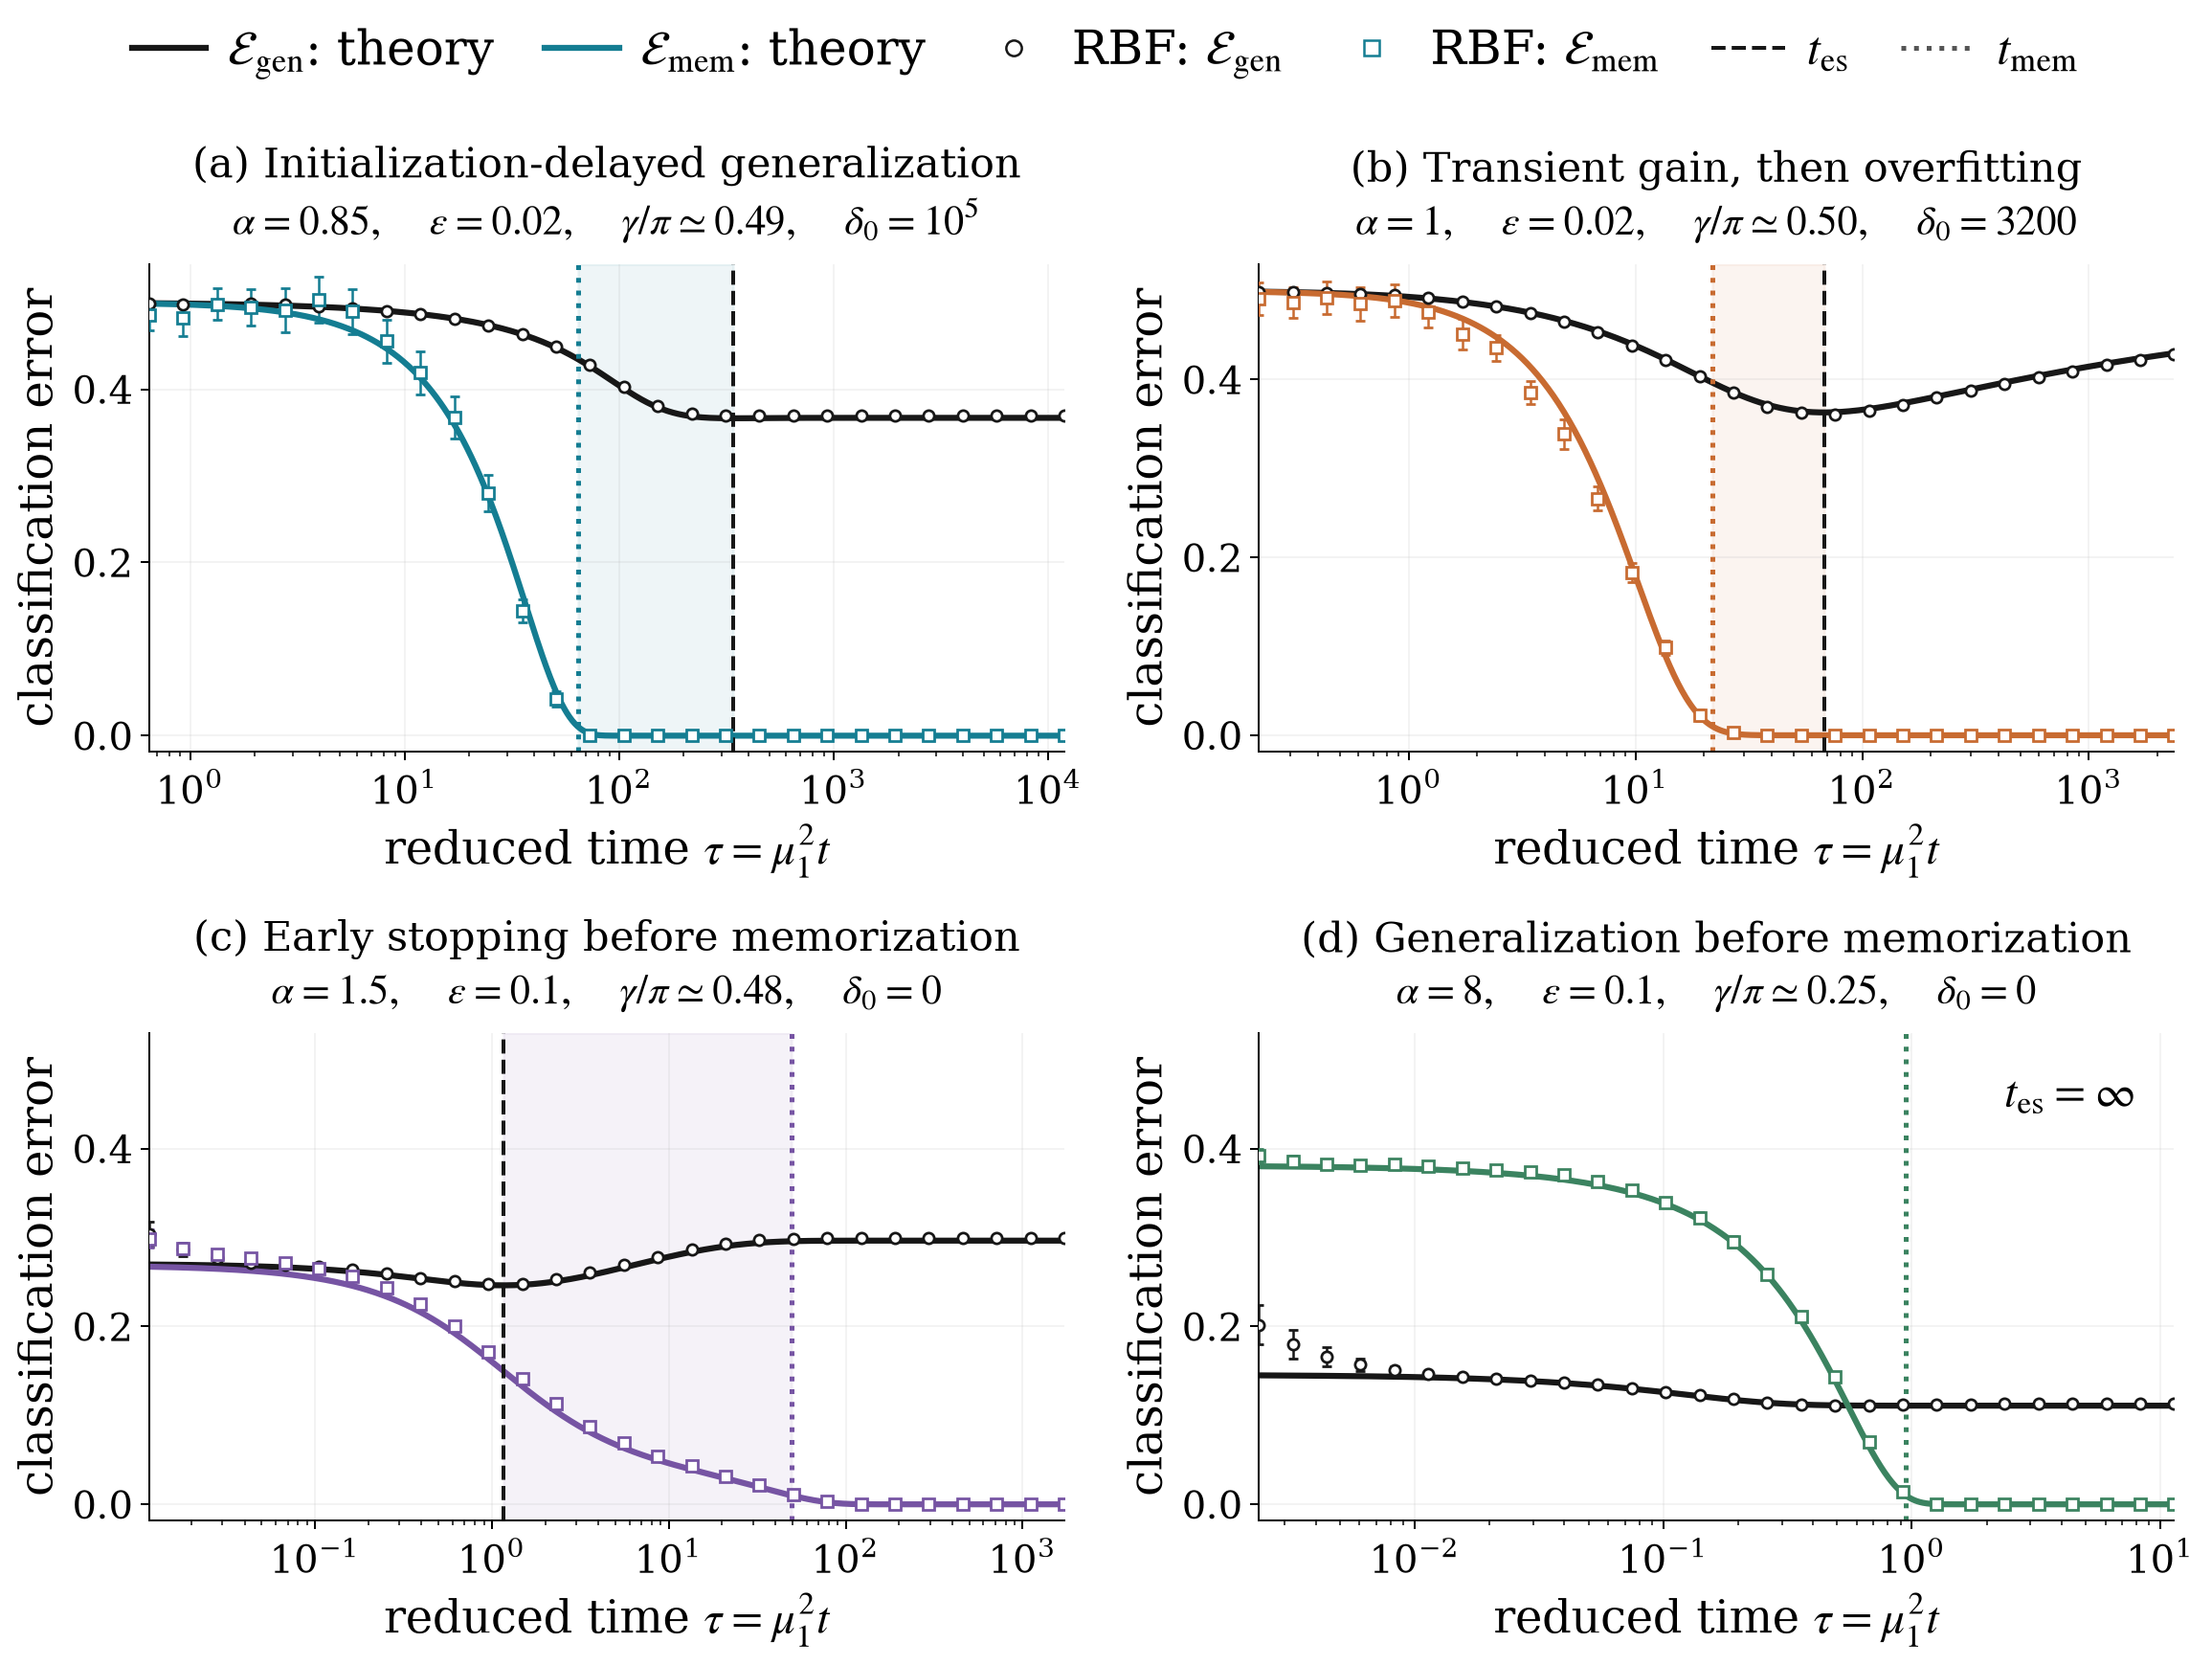

In [6]:
validation_records = get_validation_records()
print('Parameters and discrepancies between independently simulated means and theory:')
for record in validation_records:
    case=validation_Case(**record['case']); theory_at_points=validation_curves(case,record['times'])
    print(validation_summarize(case)); print(rbf_parameters(case.b))
    for key in ('E_test','E_mem'):
        values=np.array([r[key] for r in record['replicates']])
        difference=values.mean(0)-theory_at_points[key]
        print(key,'RMSE =',np.sqrt(np.mean(difference**2)),
              'max absolute difference =',np.max(np.abs(difference)))
display(Image(filename=str(OUT/'kernel_regimes_validation.png')))


In [7]:
def check_discrete_gradient_descent():
    rng=np.random.default_rng(9107)
    X=sphere_rows(rng,28,20)
    K=np.exp(-.8*(1-X@X.T/20))
    eigenvalues,eigenvectors=np.linalg.eigh(K)
    y=rng.choice([-1.,1.],len(K)); initial=rng.normal(0,.2,len(K))
    for metric,power in [('rkhs',1),('dual',2)]:
        total_time=.5/eigenvalues.max()**power
        residual=np.exp(-total_time*eigenvalues**power)
        exact=eigenvectors@((-np.expm1(-total_time*eigenvalues**power)/eigenvalues)*
              (eigenvectors.T@y)+residual*(eigenvectors.T@initial))
        errors=[]
        for steps in (256,512):
            step=total_time/steps; assert step*eigenvalues.max()**power<2
            coefficients=initial.copy()
            for _ in range(steps):
                residual=y-K@coefficients
                coefficients+=step*(residual if metric=='rkhs' else K@residual)
            errors.append(np.linalg.norm(coefficients-exact))
        assert errors[1]<.6*errors[0],(metric,errors)
        print(metric,'Euler errors after successive step halving:',errors)
check_discrete_gradient_descent()
for metric in ('rkhs','dual'):
    critical=validation_Case('critical',2.,.1,np.pi/(2*.9**2)-1,metric=metric)
    assert np.isinf(validation_stopping_time(critical))
    e=validation_curves(critical,np.geomspace(1e-5,100,250))['E_test']
    assert np.max(np.diff(e))<1e-10
print('Metric and critical-boundary checks passed.')


rkhs Euler errors after successive step halving: [np.float64(4.126339404233701e-05), np.float64(2.0621285287201192e-05)]
dual Euler errors after successive step halving: [np.float64(4.020227647588003e-05), np.float64(2.00904968073182e-05)]
Metric and critical-boundary checks passed.


In [8]:

from pathlib import Path
import os, json, hashlib, pickle, tarfile, urllib.request, time, platform
import numpy as np
import scipy
import scipy.linalg as la
import matplotlib.pyplot as plt
try:
    from threadpoolctl import threadpool_limits
except ImportError:
    from contextlib import nullcontext
    def threadpool_limits(limits):
        return nullcontext()

CIFAR_CONFIG = dict(n_train=3072, eps=0.2, seeds=list(range(5)),
                    etas=[0.05, 0.75, 6.0, 8.0, 10.0, 12.0, 16.0, 20.0, 30.0, 40.0, 60.0, 80.0],
                    metric='rkhs', n_times=481, log10_t_min=-5.0,
                    log10_t_max=5.0, blas_threads=4)
CIFAR_DATA_DIR = Path(os.environ.get('CIFAR_DATA_DIR', str(PROJECT_ROOT / 'cifar_data')))
CIFAR_FIG_DIR = OUT
CIFAR_CACHE_DIR = OUT / 'cifar_cache'
CIFAR_URL = 'https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz'
CIFAR_MD5 = 'c58f30108f718f92721af3b95e74349a'

def cifar_md5(path):
    h = hashlib.md5()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def cifar_load_official(data_dir=CIFAR_DATA_DIR):
    
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    raw_dir = data_dir / 'cifar-10-batches-py'
    if data_dir.name == 'cifar-10-batches-py':
        raw_dir = data_dir
    members = ['data_batch_' + str(i) for i in range(1, 6)] + ['test_batch']
    if all((raw_dir / m).is_file() for m in members):
        batches = []
        for m in members:
            with (raw_dir / m).open('rb') as f:
                batches.append(pickle.load(f, encoding='bytes'))
    else:
        archive = data_dir / 'cifar-10-python.tar.gz'
        if not archive.is_file():
            partial = archive.with_suffix('.download')
            print('Downloading the official CIFAR-10 archive...', flush=True)
            try:
                with urllib.request.urlopen(CIFAR_URL, timeout=60) as r, partial.open('wb') as f:
                    while block := r.read(1024*1024):
                        f.write(block)
            except Exception as e:
                raise RuntimeError('CIFAR download failed. Put the official '
                    'cifar-10-python.tar.gz archive in CIFAR_DATA_DIR, then rerun this cell.') from e
            if cifar_md5(partial) != CIFAR_MD5:
                raise RuntimeError('Official CIFAR archive checksum mismatch; download not used.')
            partial.replace(archive)
        if cifar_md5(archive) != CIFAR_MD5:
            raise RuntimeError('CIFAR archive checksum mismatch; archive not used.')
        with tarfile.open(archive, 'r:gz') as tf:
            batches = []
            for m in members:
                with tf.extractfile('cifar-10-batches-py/' + m) as f:
                    batches.append(pickle.load(f, encoding='bytes'))
    x = np.concatenate([b[b'data'] for b in batches[:5]], axis=0)
    labels = np.concatenate([np.asarray(b[b'labels'], dtype=np.int64) for b in batches[:5]])
    xt = np.asarray(batches[5][b'data'])
    lt = np.asarray(batches[5][b'labels'], dtype=np.int64)
    assert x.shape == (50000, 3072) and xt.shape == (10000, 3072)
    return x, labels, xt, lt

def cifar_raf_split(raw, seed, n_train, eps):
    
    x, labels, xt, lt = raw
    n_rule = 2 * int(round((1.0-eps)*n_train/2.0))
    n_fact = int(n_train)-n_rule
    if n_fact < 1 or n_rule < 2:
        raise ValueError('Need at least two rule examples and one factual example.')
    rng = np.random.default_rng(71000+int(seed))
    cat = rng.choice(np.flatnonzero(labels == 3), n_rule//2, replace=False)
    dog = rng.choice(np.flatnonzero(labels == 5), n_rule//2, replace=False)
    fact = rng.choice(np.flatnonzero(labels == 1), n_fact, replace=False)
    index = np.concatenate([cat, dog, fact])
    y_fact = rng.choice(np.array([-1.0, 1.0]), n_fact)
    y = np.concatenate([np.ones(n_rule//2), -np.ones(n_rule//2), y_fact])
    fact_mask = np.arange(n_train) >= n_rule
    test_index = np.concatenate([np.flatnonzero(lt == 3), np.flatnonzero(lt == 5)])
    y_test = np.concatenate([np.ones(1000), -np.ones(1000)])
    X = x[index].astype(np.float64)/255.0
    Xtest = xt[test_index].astype(np.float64)/255.0
    mean, std = X.mean(axis=0), X.std(axis=0)
    std = np.where(std < 1e-8, 1.0, std)
    X = (X-mean)/std
    Xtest = (Xtest-mean)/std
    X /= np.linalg.norm(X, axis=1, keepdims=True)
    Xtest /= np.linalg.norm(Xtest, axis=1, keepdims=True)
    split_hash = hashlib.sha256(index.astype('<i8').tobytes()+y.astype('<f8').tobytes()).hexdigest()
    return X, y, fact_mask, Xtest, y_test, split_hash

def cifar_dot_kernel(rho, eta):
    
    if eta <= 0:
        raise ValueError('eta must be positive.')
    return np.exp(-eta*(1.0-np.clip(rho, -1.0, 1.0)))

def cifar_exact_gf(K, Ktest, y, ytest, fact_mask, finite_times, metric='rkhs'):
    
    if metric not in {'rkhs', 'dual'}:
        raise ValueError("metric must be 'rkhs' or 'dual'")
    if not np.all(np.asarray(finite_times)>0):
        raise ValueError('Use strictly positive finite times (classification jumps at t=0).')
    eigenvalues, V = la.eigh(K, overwrite_a=False, check_finite=True, driver='evd')
    spectral_tol = 200*np.finfo(float).eps*max(1.0, eigenvalues[-1])
    if eigenvalues[0] <= spectral_tol:
        raise RuntimeError('Kernel is singular or too poorly conditioned for unregularized interpolation: '
                           f'min eigenvalue={eigenvalues[0]:.3g}. No ridge was added.')
    vy = V.T @ y
    rate = eigenvalues if metric == 'rkhs' else eigenvalues**2
    h = -np.expm1(-rate[:,None]*np.asarray(finite_times)[None,:])
    h = np.column_stack([h, np.ones(len(y))])
    weighted = vy[:,None]*h
    fact_scores = V[fact_mask] @ weighted
    coef = V @ (weighted/eigenvalues[:,None])
    test_scores = Ktest @ coef
    gen = np.mean((test_scores >= 0) != (ytest[:,None] >= 0), axis=0)
    mem = np.mean((fact_scores >= 0) != (y[fact_mask,None] >= 0), axis=0)
    half_mse = 0.5*np.sum((vy[:,None]*(1.0-h))**2, axis=0)/len(y)
    interpolation_error = float(np.max(np.abs(K@coef[:,-1]-y)))
    if interpolation_error > 1e-6:
        raise RuntimeError(f'Exact endpoint interpolation check failed: {interpolation_error:g}')
    assert mem[-1] == 0.0
    return dict(gen=gen, mem=mem, half_mse=half_mse,
                eigenvalue_min=float(eigenvalues[0]), eigenvalue_max=float(eigenvalues[-1]),
                endpoint_residual=interpolation_error)

def validate_cifar_result_arrays(result, shape, n_fact, label='CIFAR'):
    classification_array(result['gen'], shape, label+' test', count=2000)
    classification_array(result['mem'], shape, label+' memorization', count=n_fact)
    mse = np.asarray(result['half_mse'])
    if mse.shape != tuple(shape) or not np.all(np.isfinite(mse)) or np.any(mse < 0):
        raise CacheMismatch(label+' has invalid square-loss values.')
    if np.any(result['mem'][...,-1] != 0) or np.any(mse[...,-1] > 1e-12):
        raise CacheMismatch(label+' endpoint does not interpolate.')

def read_matching_cifar(path, protocol):
    config = protocol['config']
    times = np.r_[np.logspace(config['log10_t_min'],config['log10_t_max'],config['n_times']),np.inf]
    shape = (len(config['seeds']),len(config['etas']),len(times))
    n_fact = config['n_train']-2*int(round((1-config['eps'])*config['n_train']/2))
    with np.load(path, allow_pickle=False) as z:
        metadata = json.loads(str(z['metadata']))
        if metadata['protocol'] != protocol:
            raise CacheMismatch('CIFAR protocol/configuration differs.')
        cached = {k:z[k].copy() for k in ('gen','mem','half_mse','times')}
    require_close(cached['times'],times,'CIFAR time grid')
    validate_cifar_result_arrays(cached,shape,n_fact)
    diagnostics = metadata['diagnostics']
    pairs = [(int(s),float(e)) for s in config['seeds'] for e in config['etas']]
    if [(d['seed'],d['eta']) for d in diagnostics] != pairs:
        raise CacheMismatch('CIFAR diagnostic seed/bandwidth coverage differs.')
    for d in diagnostics:
        eigen_min, eigen_max, residual = d['eigenvalue_min'],d['eigenvalue_max'],d['endpoint_residual']
        if (not np.isfinite([eigen_min,eigen_max,residual]).all()
                or not 0 < eigen_min <= eigen_max or not 0 <= residual <= 1e-6
                or not isinstance(d['split_hash'],str) or len(d['split_hash']) != 64):
            raise CacheMismatch('Invalid CIFAR kernel/interpolation diagnostic.')
    return dict(**cached,diagnostics=diagnostics,protocol=protocol,software=metadata['software'])

def save_cifar_results(results, path, summary=None):
    metadata = dict(protocol=results['protocol'],diagnostics=results['diagnostics'],
                    software=results['software'])
    if summary is not None:
        metadata['summary'] = summary
    atomic_npz(path, **{k:results[k] for k in ('gen','mem','half_mse','times')},
               metadata=json.dumps(metadata,sort_keys=True))

def read_matching_cifar_checkpoint(path, protocol, split_hash, n_fact):
    with np.load(path,allow_pickle=False) as z:
        if str(z['split_hash']) != split_hash or json.loads(str(z['protocol'])) != protocol:
            raise CacheMismatch('CIFAR checkpoint split or protocol differs.')
        result = {k:z[k].copy() for k in ('gen','mem','half_mse','eigenvalue_min',
                                          'eigenvalue_max','endpoint_residual')}
    validate_cifar_result_arrays(result,(protocol['config']['n_times']+1,),n_fact)
    lo,hi,res = (float(result[k]) for k in ('eigenvalue_min','eigenvalue_max','endpoint_residual'))
    if not np.isfinite([lo,hi,res]).all() or not 0 < lo <= hi or not 0 <= res <= 1e-6:
        raise CacheMismatch('CIFAR checkpoint eigenvalues or residual invalid.')
    return result


def cifar_run(config=CIFAR_CONFIG, data_dir=CIFAR_DATA_DIR, cache_dir=CIFAR_CACHE_DIR,
              force_recompute=None):
    
    force_recompute = CIFAR_FORCE_RECOMPUTE if force_recompute is None else force_recompute
    cache_dir = Path(cache_dir); cache_dir.mkdir(parents=True, exist_ok=True)
    finite_times = np.logspace(config['log10_t_min'],config['log10_t_max'],config['n_times'])
    shape = (len(config['seeds']),len(config['etas']),len(finite_times)+1)
    gen, mem, mse = (np.empty(shape) for _ in range(3))
    diagnostics = []
    protocol = {'version':'cifar-raf-exact-raw-rbf-gf-v2','archive_md5':CIFAR_MD5,
                'split_rng_offset':71000,'normalization':'train-pixel-zscore-float64-then-unit-row',
                'kernel':'raw-unit-diagonal-rbf-with-constant-term',
                'classes':{'cat':1,'dog':-1,'automobile':'independent Rademacher'},
                'config':config}
    fingerprint=hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()[:16]
    aggregate = cache_dir / f'cifar_kernel_results_{fingerprint}.npz'
    if not force_recompute:
        cached = checked_cache([aggregate, publication_cache('cifar_cache/cifar_kernel_results.npz'),
                                cache_dir/'cifar_kernel_results.npz'],
                               lambda p: read_matching_cifar(p,protocol))
        if cached is not None:
            save_cifar_results(cached,aggregate)
            print('Using completed, verified CIFAR experiments; set CIFAR_FORCE_RECOMPUTE=True to rerun.')
            return cached
    raw = cifar_load_official(data_dir)
    with threadpool_limits(limits=config['blas_threads']):
        for si,seed in enumerate(config['seeds']):
            X,y,fact_mask,Xtest,ytest,split_hash = cifar_raf_split(raw,seed,config['n_train'],config['eps'])
            rho=X@X.T; np.fill_diagonal(rho,1.0)
            rhot=Xtest@X.T
            for ki,eta in enumerate(config['etas']):
                checkpoint=cache_dir/f'{fingerprint}_seed{seed}_eta{eta:g}.npz'
                tic=time.time()
                result = None if force_recompute else checked_cache([checkpoint],
                    lambda p: read_matching_cifar_checkpoint(p,protocol,split_hash,int(fact_mask.sum())))
                if result is None:
                    K=cifar_dot_kernel(rho,eta); np.fill_diagonal(K,1.0)
                    Ktest=cifar_dot_kernel(rhot,eta)
                    result=cifar_exact_gf(K,Ktest,y,ytest,fact_mask,finite_times,config['metric'])
                    atomic_npz(checkpoint,**result,split_hash=split_hash,
                               protocol=json.dumps(protocol,sort_keys=True))
                gen[si,ki]=result['gen']; mem[si,ki]=result['mem']; mse[si,ki]=result['half_mse']
                diagnostics.append(dict(seed=int(seed),eta=float(eta),split_hash=split_hash,
                                        eigenvalue_min=float(result['eigenvalue_min']),
                                        eigenvalue_max=float(result['eigenvalue_max']),
                                        endpoint_residual=float(result['endpoint_residual'])))
                print(f'CIFAR seed={seed}, eta={eta:g}: best={gen[si,ki].min():.4f}, '
                      f'end={gen[si,ki,-1]:.4f}, mem(end)={mem[si,ki,-1]:.4f}; '
                      f'{time.time()-tic:.1f}s',flush=True)
    return dict(gen=gen,mem=mem,half_mse=mse,times=np.r_[finite_times,np.inf],
                diagnostics=diagnostics,protocol=protocol,
                software={'python':platform.python_version(),'numpy':np.__version__,
                          'scipy':scipy.__version__})

def cifar_report(results):
    
    g=results['gen']; cfg=results['protocol']['config']; out=[]
    nseed=g.shape[0]
    print('eta | endpoint mean ± sample SD | mean per-seed grid-oracle gap | gap of mean curve')
    for ki,eta in enumerate(cfg['etas']):
        gap=g[:,ki,-1]-g[:,ki,:].min(axis=1)
        m=g[:,ki,:].mean(axis=0)
        out.append(dict(eta=eta,end_mean=float(m[-1]),end_sd=float(g[:,ki,-1].std(ddof=1)) if nseed>1 else 0.0,
                        mean_per_seed_gap=float(gap.mean()),gap_of_mean=float(m[-1]-m.min()),
                        min_mean=float(m.min()),
                        first_mean_opt_time=(float(results['times'][m.argmin()])
                                             if np.isfinite(results['times'][m.argmin()]) else 'infinity'),
                        endpoint_is_grid_minimum=bool(m[-1]<=m.min()+1e-12),
                        all_seed_endpoint_fact_errors_zero=bool(np.all(results['mem'][:,ki,-1]==0))))
        z=out[-1]
        print(f"{eta:5g} | {z['end_mean']:.4f} ± {z['end_sd']:.4f} | "
              f"{z['mean_per_seed_gap']:.4f} | {z['gap_of_mean']:.4f}")
    return out

def cifar_plot(results, output_dir=CIFAR_FIG_DIR):
    
    from matplotlib.lines import Line2D
    from matplotlib.ticker import MultipleLocator
    cfg=results['protocol']['config']; gen=results['gen']; mem=results['mem']
    gm,mm=gen.mean(axis=0),mem.mean(axis=0)
    candidates=[i for i,e in enumerate(cfg['etas']) if 6 <= e <= 16]
    selected=cfg['etas'][min(candidates,key=lambda i:gm[i,-1])]
    display=[0.05,0.75,float(selected),20.0,80.0]
    print('Appendix CIFAR figure displays eta=', display,
          '; all tested eta values are retained in the preceding report.')
    colors=['#0072B2','#009E73','#D55E00','#CC79A7','#5C5C5C']
    output_dir=Path(output_dir); output_dir.mkdir(parents=True,exist_ok=True)
    style={'font.family':'serif','font.serif':['DejaVu Serif'],'mathtext.fontset':'stix',
           'font.size':15,'axes.labelsize':18,'xtick.labelsize':14,'ytick.labelsize':14,
           'legend.fontsize':13,'axes.spines.top':False,'axes.spines.right':False,
           'axes.linewidth':0.8,'pdf.fonttype':42,'ps.fonttype':42}
    with plt.rc_context(style):
        fig,ax=plt.subplots(figsize=(7.8,5.55))
        for col,eta in zip(colors,display):
            ki=cfg['etas'].index(eta); gx,gy=gm[ki],mm[ki]
            ax.plot(gx,gy,lw=2.1,color=col,label=rf'$\eta={eta:g}$',alpha=.95)
            
            j=(len(gx)-1 if gx[-1] <= gx.min()+1e-12 else int(np.argmin(gx)))
            ax.plot(gx[-1],gy[-1],marker='s',ms=7.0,mfc=col,mec='white',
                    mew=.6,zorder=5,clip_on=False)
            ax.plot(gx[j],gy[j],marker='*',ms=14,mfc='white',mec=col,
                    mew=1.4,zorder=6,clip_on=False)
            arc=np.r_[0,np.cumsum(np.hypot(np.diff(gx),np.diff(gy)))]; total=arc[-1]
            if total>0:
                for frac in (0.37,0.71):
                    jj=min(max(1,np.searchsorted(arc,frac*total)),len(gx)-2)
                    kk=min(jj+max(2,len(gx)//100),len(gx)-1)
                    ax.annotate('',xy=(gx[kk],gy[kk]),xytext=(gx[jj],gy[jj]),
                                arrowprops=dict(arrowstyle='-|>',color=col,lw=1.3,
                                                mutation_scale=13))
        ax.set(xlabel=r'Generalization error $\mathcal{E}_{\rm gen}$',
               ylabel=r'Memorization error $\mathcal{E}_{\rm mem}$',ylim=(-.014,.525))
        use=[cfg['etas'].index(e) for e in display]
        ax.set_xlim(max(0,float(gm[use].min())-.012),
                    min(.55,float(gm[use].max())+.006))
        ax.xaxis.set_major_locator(MultipleLocator(.025))
        ax.yaxis.set_major_locator(MultipleLocator(.1))
        ax.grid(alpha=.14,lw=.6)
        handles,labels=ax.get_legend_handles_labels()
        bandwidth_legend=fig.legend(handles,labels,loc='upper center',
                   bbox_to_anchor=(.555,1.005),ncol=5,frameon=False,
                   columnspacing=1.0,handlelength=1.55)
        markers=[Line2D([],[],color='#333333',marker='*',ms=12,mfc='white',
                        mec='#333333',mew=1.2,lw=0),
                 Line2D([],[],color='#333333',marker='s',ms=6.7,lw=0)]
        fig.legend(markers,[r'Minimum measured $\mathcal{E}_{\rm gen}$',
                            r'Interpolation ($t=\infty$)'],
                   loc='upper center',bbox_to_anchor=(.555,.949),ncol=2,
                   frameon=False,columnspacing=1.9,handlelength=1.4)
        fig.subplots_adjust(left=.14,right=.985,bottom=.145,top=.83)
        fig.savefig(output_dir/'cifar_kernel_dynamics.pdf',bbox_inches='tight')
        fig.savefig(output_dir/'cifar_kernel_dynamics.png',dpi=200,bbox_inches='tight')
        plt.show()
    return fig


In [9]:
cifar_results = cifar_run()
cifar_summaries = cifar_report(cifar_results)
cifar_fingerprint = hashlib.sha256(json.dumps(cifar_results['protocol'],sort_keys=True).encode()).hexdigest()[:16]
save_cifar_results(cifar_results,
    CIFAR_CACHE_DIR/f'cifar_kernel_results_{cifar_fingerprint}.npz',cifar_summaries)
_ = (CIFAR_CACHE_DIR/f'cifar_kernel_summary_{cifar_fingerprint}.json').write_text(
    json.dumps(cifar_summaries,indent=2))


Loaded matching data: cifar_kernel_results.npz
Using completed, verified CIFAR experiments; set CIFAR_FORCE_RECOMPUTE=True to rerun.
eta | endpoint mean ± sample SD | mean per-seed grid-oracle gap | gap of mean curve
 0.05 | 0.4225 ± 0.0046 | 0.0392 | 0.0349
 0.75 | 0.3975 ± 0.0082 | 0.0328 | 0.0302
    6 | 0.3650 ± 0.0058 | 0.0057 | 0.0034
    8 | 0.3649 ± 0.0048 | 0.0025 | 0.0012
   10 | 0.3710 ± 0.0044 | 0.0027 | 0.0009
   12 | 0.3753 ± 0.0060 | 0.0015 | 0.0003
   16 | 0.3806 ± 0.0106 | 0.0008 | 0.0001
   20 | 0.3858 ± 0.0074 | 0.0027 | 0.0010
   30 | 0.3911 ± 0.0089 | 0.0023 | 0.0007
   40 | 0.4008 ± 0.0080 | 0.0017 | 0.0014
   60 | 0.4143 ± 0.0049 | 0.0005 | 0.0002
   80 | 0.4169 ± 0.0042 | 0.0001 | 0.0000


Appendix CIFAR figure displays eta= [0.05, 0.75, 8.0, 20.0, 80.0] ; all tested eta values are retained in the preceding report.


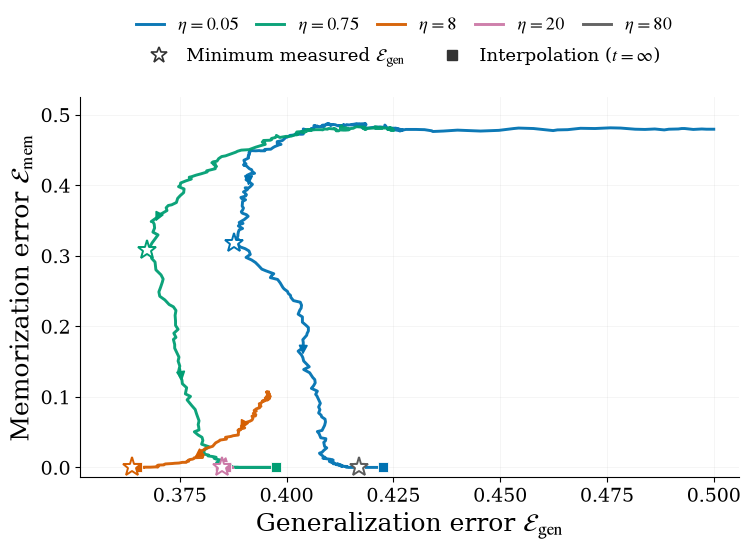

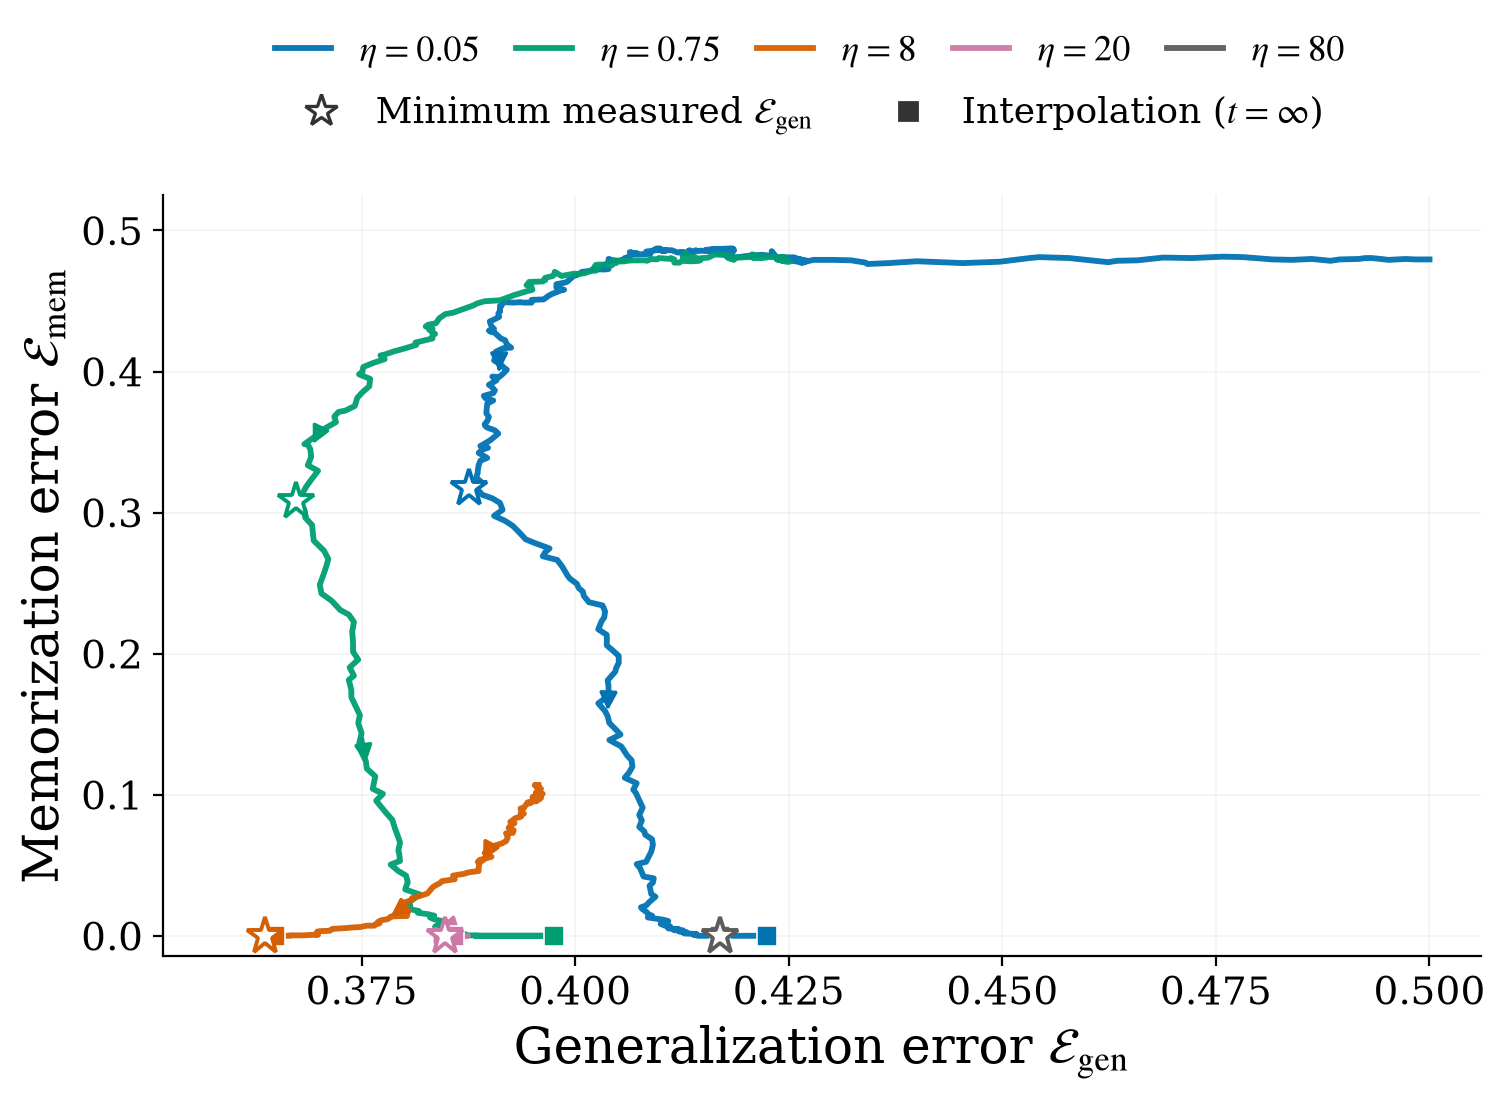

In [10]:
cifar_figure = cifar_plot(cifar_results)

plt.close(cifar_figure)
display(Image(filename=str(OUT/'cifar_kernel_dynamics.png')))


eta | max seed test difference (last finite vs infinity) | max half-MSE | residual contraction bound
 0.05 | 0.0005 | 8.266e-07 | 2.010e-01
 0.75 | 0 | 0.000e+00 | 7.673e-113
    6 | 0 | 0.000e+00 | 0.000e+00
    8 | 0 | 0.000e+00 | 0.000e+00
   10 | 0 | 0.000e+00 | 0.000e+00
   12 | 0 | 0.000e+00 | 0.000e+00
   16 | 0 | 0.000e+00 | 0.000e+00
   20 | 0 | 0.000e+00 | 0.000e+00
   30 | 0 | 0.000e+00 | 0.000e+00
   40 | 0 | 0.000e+00 | 0.000e+00
   60 | 0 | 0.000e+00 | 0.000e+00
   80 | 0 | 0.000e+00 | 0.000e+00
Saved: Figures/cifar_kernel_time_span.pdf
Saved: Figures/cifar_kernel_time_span.png


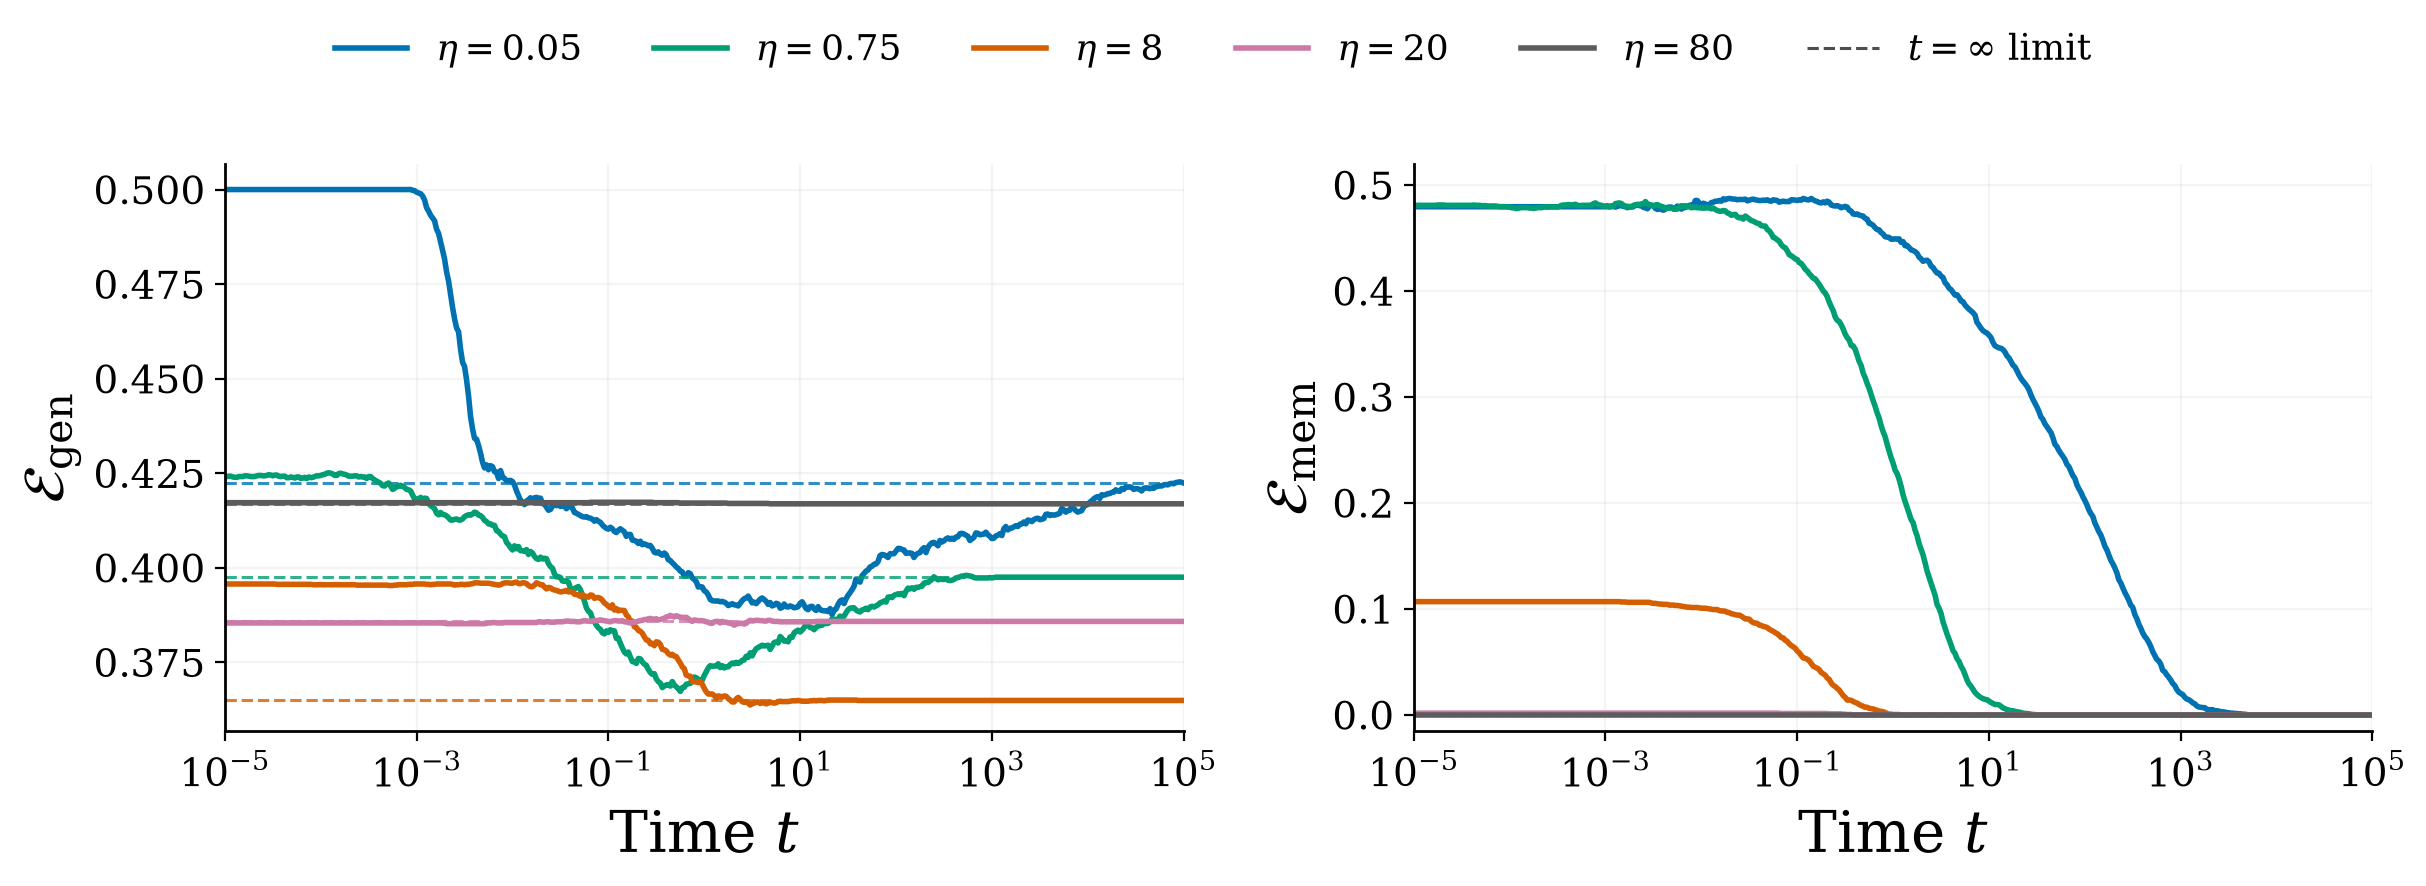

In [11]:
import csv
cfg = cifar_results['protocol']['config']
finite_t = cifar_results['times'][:-1]
assert len(finite_t) == cfg['n_times'] and np.isinf(cifar_results['times'][-1])
assert np.all(np.diff(finite_t) > 0)
time_audit = []
for ki, eta in enumerate(cfg['etas']):
    ds = [d for d in cifar_results['diagnostics'] if d['eta'] == eta]
    min_eig = min(d['eigenvalue_min'] for d in ds)
    g, m, loss = (cifar_results[k][:, ki] for k in ('gen','mem','half_mse'))
    time_audit.append(dict(eta=float(eta),t_min=float(finite_t[0]),t_max=float(finite_t[-1]),
        min_kernel_eigenvalue=float(min_eig),
        worst_residual_contraction_bound=float(np.exp(-finite_t[-1]*min_eig)),
        maximum_seed_test_difference_last_vs_endpoint=float(np.max(np.abs(g[:,-2]-g[:,-1]))),
        maximum_seed_mem_difference_last_vs_endpoint=float(np.max(np.abs(m[:,-2]-m[:,-1]))),
        maximum_seed_half_mse_last=float(loss[:,-2].max()),
        maximum_endpoint_residual=max(d['endpoint_residual'] for d in ds)))
with (OUT/'cifar_time_span_check.csv').open('w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(time_audit[0]));writer.writeheader();writer.writerows(time_audit)
save_json('cifar_time_span_check.json',time_audit)
print('eta | max seed test difference (last finite vs infinity) | max half-MSE | residual contraction bound')
for r in time_audit:
    print(f"{r['eta']:5g} | {r['maximum_seed_test_difference_last_vs_endpoint']:.6g} | "
          f"{r['maximum_seed_half_mse_last']:.3e} | {r['worst_residual_contraction_bound']:.3e}")
selected_etas=(.05,.75,8.,20.,80.)
colors=('#0072B2','#009E73','#D55E00','#CC79A7','#5C5C5C')
with plt.rc_context(PLOT_STYLE):
    fig,axs=plt.subplots(1,2,figsize=(11.8,4.5),sharex=True)
    for eta,color in zip(selected_etas,colors):
        ki=cfg['etas'].index(eta)
        for ax,key in zip(axs,('gen','mem')):
            mean=cifar_results[key][:,ki].mean(axis=0)
            ax.plot(finite_t,mean[:-1],color=color,lw=2,label=rf'$\eta={eta:g}$')
            ax.axhline(mean[-1],color=color,lw=1.1,ls='--',alpha=.8)
    for ax in axs:
        ax.set_xscale('log');ax.set_xlim(finite_t[0],finite_t[-1]);ax.set_xlabel(r'Time $t$')
        ax.grid(alpha=.13);ax.tick_params(labelsize=14)
    axs[0].set_ylabel(r'$\mathcal{E}_{\rm gen}$');axs[1].set_ylabel(r'$\mathcal{E}_{\rm mem}$')
    axs[1].set_ylim(-.015,.52)
    handles,labels=axs[0].get_legend_handles_labels()
    handles.append(Line2D([],[],color='.3',ls='--',lw=1.1));labels.append(r'$t=\infty$ limit')
    fig.legend(handles,labels,loc='upper center',ncol=6,frameon=False,fontsize=13)
    fig.subplots_adjust(left=.075,right=.985,bottom=.19,top=.82,wspace=.24)
    save_figure(fig,'cifar_kernel_time_span')
display(Image(filename=str(OUT/'cifar_kernel_time_span.png')))


In [12]:

expected_pdfs = ['kernel_regimes_validation.pdf', 'cifar_kernel_dynamics.pdf', 'cifar_kernel_time_span.pdf']
for filename in expected_pdfs:
    data = (OUT/filename).read_bytes()
    assert data.startswith(b'%PDF-') and b'%%EOF' in data[-100:], filename

print('Kernel checks completed.')


Kernel checks completed.
